In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import EarlyStopping

df = pd.read_csv('creditcard1.csv')
print(f"Dimensi dataset awal: {df.shape}")

Dimensi dataset awal: (284807, 31)


In [3]:
X = df.drop('Class', axis=1)
y = df['Class']

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [5]:
# 2. FILTER DATA TRAIN: Ambil yang transaksi SAH (0) saja untuk melatih Autoencoder
X_train_sah = X_train[y_train == 0]

In [6]:
from sklearn.preprocessing import RobustScaler
# 3. PROSES SCALING (Menggunakan RobustScaler)
print("Mengubah metode scaling ke RobustScaler...")
scaler_robust = RobustScaler()

# PERBAIKAN PENTING: Fit & Transform HANYA pada X_train_sah (yang sudah bersih)
X_train_sah_scaled = scaler_robust.fit_transform(X_train_sah)

# Transform data testing
X_test_scaled = scaler_robust.transform(X_test)
print("Scaling selesai! Data siap dilatih.\n")

Mengubah metode scaling ke RobustScaler...
Scaling selesai! Data siap dilatih.



In [10]:
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Model

print("Membangun model Autoencoder dengan arsitektur yang di-upgrade...")

input_dim = X_train_sah_scaled.shape[1]
input_layer = Input(shape=(input_dim,))

# --- ENCODER ---
encoded = Dense(128, activation='relu')(input_layer)
encoded = BatchNormalization()(encoded) # Menstabilkan pembelajaran
encoded = Dropout(0.2)(encoded)         # Mencegah overfitting

encoded = Dense(64, activation='relu')(encoded)
encoded = BatchNormalization()(encoded)

latent = Dense(32, activation='relu')(encoded) # Representasi inti

# --- DECODER ---
decoded = Dense(64, activation='relu')(latent)
decoded = BatchNormalization()(decoded)

decoded = Dense(128, activation='relu')(decoded)
decoded = BatchNormalization()(decoded)
decoded = Dropout(0.2)(decoded)         # Mencegah overfitting

# Output Layer (Linear & MSE untuk RobustScaler)
output_layer = Dense(input_dim, activation='linear')(decoded) 

# Kompilasi Model
ae_benar = Model(inputs=input_layer, outputs=output_layer)
ae_benar.compile(optimizer='adam', loss='mse')
print("Model siap dilatih!")

Membangun model Autoencoder dengan arsitektur yang di-upgrade...
Model siap dilatih!


In [11]:
# 5. PELATIHAN MODEL DENGAN EARLY STOPPING
print("Memulai pelatihan model Autoencoder...")
# Akan berhenti otomatis jika dalam 3 epoch berturut-turut val_loss tidak membaik
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history = ae_benar.fit(
    X_train_sah_scaled, X_train_sah_scaled, # Targetnya adalah merekonstruksi data input
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)
print("Pelatihan selesai!")

Memulai pelatihan model Autoencoder...
Epoch 1/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 14s 3ms/step - loss: 0.8211 - val_loss: 0.3719
Epoch 2/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - loss: 0.5361 - val_loss: 0.2762
Epoch 3/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 14s 4ms/step - loss: 0.4813 - val_loss: 0.3608
Epoch 4/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - loss: 0.4471 - val_loss: 0.3215
Epoch 5/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - loss: 0.4224 - val_loss: 0.3718
Pelatihan selesai!


In [12]:
import numpy as np
from sklearn.metrics import precision_recall_curve, roc_auc_score, classification_report

# ==========================================
# 1. HITUNG ERROR REKONSTRUKSI
# ==========================================
print("Menghitung error rekonstruksi pada data testing...")
X_test_predictions = ae_benar.predict(X_test_scaled)

# Menggunakan Mean Squared Error (sesuai dengan loss function 'mse' yang baru)
reconstruction_errors = np.mean(np.power(X_test_scaled - X_test_predictions, 2), axis=1)

# ==========================================
# 2. EVALUASI SKOR AUC (Target Jurnal: > 0.93)
# ==========================================
auc_score = roc_auc_score(y_test, reconstruction_errors)
print("\n=== HASIL EVALUASI TARGET JURNAL ===")
print(f"Skor AUC Model Anda : {auc_score:.4f}")
if auc_score > 0.93:
    print("✅ TARGET AUC TERCAPAI!")
else:
    print("❌ Target AUC belum tercapai.")

# ==========================================
# 3. CARI THRESHOLD UNTUK RECALL >= 0.91
# ==========================================
precision, recall, thresholds = precision_recall_curve(y_test, reconstruction_errors)

# Cari semua index di mana Recall masih memenuhi syarat jurnal (>= 91%)
indices_memenuhi_syarat = np.where(recall >= 0.91)[0]

# Jika model mampu mencapai recall 91%
if len(indices_memenuhi_syarat) > 0:
    # Ambil threshold tertinggi yang masih mempertahankan recall 91%
    index_target = indices_memenuhi_syarat[-1] 
    threshold_jurnal = thresholds[index_target]
    
    # ==========================================
    # 4. TERAPKAN THRESHOLD & TAMPILKAN LAPORAN
    # ==========================================
    y_pred_jurnal = (reconstruction_errors > threshold_jurnal).astype(int)
    
    print(f"\nBatas Ambang (Threshold) untuk Recall >= 91% : {threshold_jurnal:.8f}")
    print("\n=== CLASSIFICATION REPORT FINAL ===")
    print(classification_report(y_test, y_pred_jurnal, target_names=['Sah (0)', 'Penipuan (1)']))

else:
    print("\n⚠️ Peringatan: Model saat ini belum mampu mencapai Recall 91%.")

Menghitung error rekonstruksi pada data testing...
1781/1781 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step

=== HASIL EVALUASI TARGET JURNAL ===
Skor AUC Model Anda : 0.9586
✅ TARGET AUC TERCAPAI!

Batas Ambang (Threshold) untuk Recall >= 91% : 0.10936849

=== CLASSIFICATION REPORT FINAL ===
              precision    recall  f1-score   support

     Sah (0)       1.00      0.83      0.91     56864
Penipuan (1)       0.01      0.91      0.02        98

    accuracy                           0.83     56962
   macro avg       0.50      0.87      0.46     56962
weighted avg       1.00      0.83      0.90     56962



In [13]:
from sklearn.ensemble import RandomForestClassifier
import numpy as np

print("=== 1. PERSIAPAN DATA HYBRID ===")
# Karena Random Forest butuh kunci jawaban (Supervised), 
# kita harus pakai X_train UTUH (yang ada penipuannya) dari hasil split paling awal!
# Pastikan Anda punya variabel X_train utuh sebelum difilter menjadi X_train_sah
X_train_utuh_scaled = scaler_robust.transform(X_train) 

# Suruh Autoencoder (Sang Detektif) menilai seluruh data training utuh
print("Autoencoder sedang menghitung skor keanehan data training...")
X_train_pred = ae_benar.predict(X_train_utuh_scaled)
error_train = np.mean(np.power(X_train_utuh_scaled - X_train_pred, 2), axis=1)

# Gabungkan data asli dengan skor keanehan (menjadi 1 fitur tambahan di kolom paling kanan)
X_train_hybrid = np.column_stack((X_train_utuh_scaled, error_train))
# (Untuk testing, kita pakai reconstruction_errors yang sudah dihitung di cell sebelumnya)
X_test_hybrid = np.column_stack((X_test_scaled, reconstruction_errors)) 

print("\n=== 2. MELATIH SANG HAKIM AGUNG (RANDOM FOREST) ===")
# Kita gunakan class_weight='balanced' agar Random Forest fokus pada kelas Penipuan yang sedikit
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1)
rf_model.fit(X_train_hybrid, y_train)

print("\n=== 3. EVALUASI TARGET JURNAL (HYBRID) ===")
# Dapatkan probabilitas (tingkat keyakinan) dari Random Forest
y_pred_prob = rf_model.predict_proba(X_test_hybrid)[:, 1]

# Cek Skor AUC
auc_hybrid = roc_auc_score(y_test, y_pred_prob)
print(f"Skor AUC Hybrid Anda : {auc_hybrid:.4f}")

# Cari Threshold Paksaan untuk Recall >= 91%
precision_h, recall_h, thresholds_h = precision_recall_curve(y_test, y_pred_prob)
indices_memenuhi_syarat_h = np.where(recall_h >= 0.91)[0]
index_target_h = indices_memenuhi_syarat_h[-1] 
threshold_hybrid = thresholds_h[index_target_h]

# Terapkan Threshold Hybrid
y_pred_final_hybrid = (y_pred_prob > threshold_hybrid).astype(int)

print(f"\nBatas Ambang (Threshold) Hybrid untuk Recall >= 91% : {threshold_hybrid:.8f}")
print("\n=== CLASSIFICATION REPORT HYBRID FINAL ===")
print(classification_report(y_test, y_pred_final_hybrid, target_names=['Sah (0)', 'Penipuan (1)']))

=== 1. PERSIAPAN DATA HYBRID ===
Autoencoder sedang menghitung skor keanehan data training...
7121/7121 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step

=== 2. MELATIH SANG HAKIM AGUNG (RANDOM FOREST) ===

=== 3. EVALUASI TARGET JURNAL (HYBRID) ===
Skor AUC Hybrid Anda : 0.9479

Batas Ambang (Threshold) Hybrid untuk Recall >= 91% : 0.00000000

=== CLASSIFICATION REPORT HYBRID FINAL ===
              precision    recall  f1-score   support

     Sah (0)       1.00      0.98      0.99     56864
Penipuan (1)       0.07      0.90      0.13        98

    accuracy                           0.98     56962
   macro avg       0.54      0.94      0.56     56962
weighted avg       1.00      0.98      0.99     56962



In [ ]:
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, precision_recall_curve, classification_report
import numpy as np

print("=== 1. MENERAPKAN SMOTE PADA DATA HYBRID ===")
smote = SMOTE(random_state=42)
X_train_hybrid_smote, y_train_smote = smote.fit_resample(X_train_hybrid, y_train)

print("Distribusi kelas SEBELUM SMOTE :")
print(y_train.value_counts() if hasattr(y_train, 'value_counts') else dict(zip(*np.unique(y_train, return_counts=True))))
print("\nDistribusi kelas SESUDAH SMOTE :")
print(y_train_smote.value_counts() if hasattr(y_train_smote, 'value_counts') else dict(zip(*np.unique(y_train_smote, return_counts=True))))

print("\n=== 2. MELATIH RANDOM FOREST DENGAN DATA SMOTE ===")
rf_smote = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_smote.fit(X_train_hybrid_smote, y_train_smote)

print("\n=== 3. EVALUASI TARGET JURNAL (HYBRID + SMOTE) ===")
y_pred_prob_smote = rf_smote.predict_proba(X_test_hybrid)[:, 1]

auc_smote = roc_auc_score(y_test, y_pred_prob_smote)
print(f"Skor AUC Hybrid+SMOTE Anda : {auc_smote:.4f}")

precision_s, recall_s, thresholds_s = precision_recall_curve(y_test, y_pred_prob_smote)
indices_memenuhi_syarat_s = np.where(recall_s >= 0.91)[0]

if len(indices_memenuhi_syarat_s) > 0:
    index_target_s = indices_memenuhi_syarat_s[-1] 
    threshold_smote = thresholds_s[index_target_s]

    y_pred_final_smote = (y_pred_prob_smote > threshold_smote).astype(int)

    print(f"\nBatas Ambang (Threshold) SMOTE untuk Recall >= 91% : {threshold_smote:.8f}")
    print("\n=== CLASSIFICATION REPORT HYBRID + SMOTE ===")
    print(classification_report(y_test, y_pred_final_smote, target_names=['Sah (0)', 'Penipuan (1)']))
else:
    print("Model masih kesulitan mencapai Recall 91%.")

=== 1. MENERAPKAN SMOTE PADA DATA HYBRID ===
Distribusi kelas SEBELUM SMOTE :
Class
0    227451
1       394
Name: count, dtype: int64

Distribusi kelas SESUDAH SMOTE :
Class
0    227451
1    227451
Name: count, dtype: int64

=== 2. MELATIH RANDOM FOREST DENGAN DATA SMOTE ===

=== 3. EVALUASI TARGET JURNAL (HYBRID + SMOTE) ===
Skor AUC Hybrid+SMOTE Anda : 0.9727

Batas Ambang (Threshold) SMOTE untuk Recall >= 91% : 0.06000000

=== CLASSIFICATION REPORT HYBRID + SMOTE ===
              precision    recall  f1-score   support

     Sah (0)       1.00      0.99      1.00     56864
Penipuan (1)       0.17      0.91      0.28        98

    accuracy                           0.99     56962
   macro avg       0.58      0.95      0.64     56962
weighted avg       1.00      0.99      0.99     56962



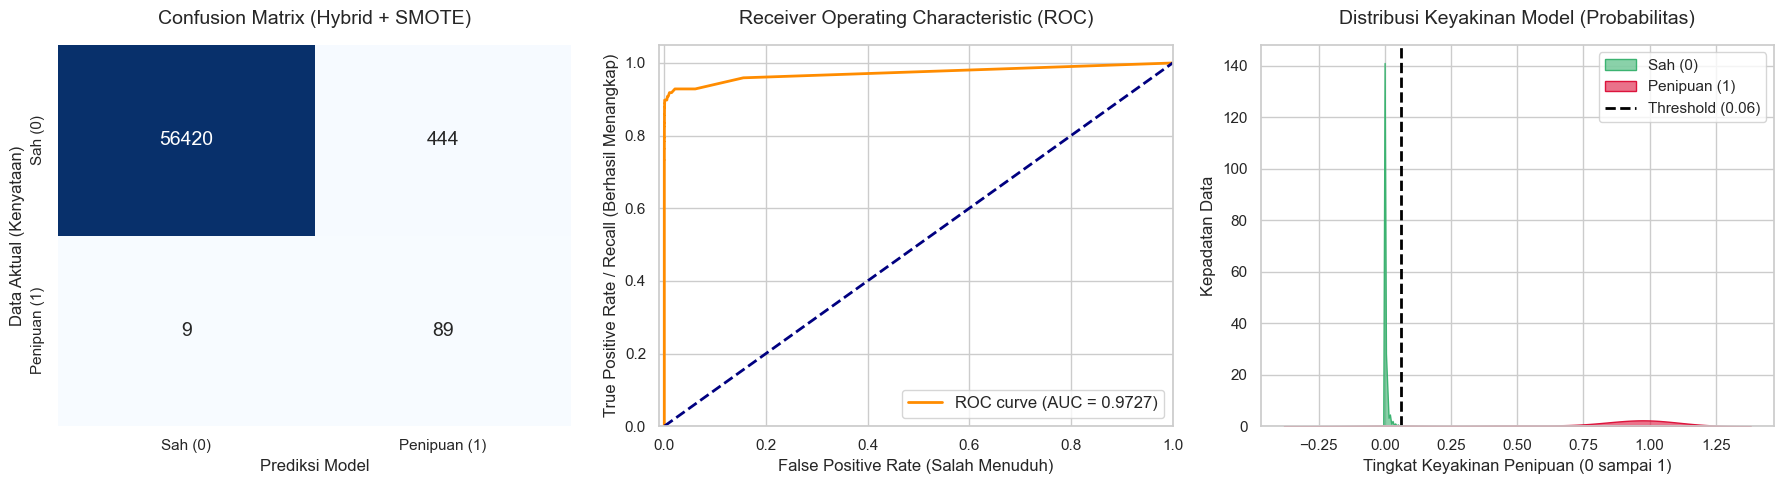

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

cm = confusion_matrix(y_test, y_pred_final_smote)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Sah (0)', 'Penipuan (1)'],
            yticklabels=['Sah (0)', 'Penipuan (1)'], 
            ax=axes[0], annot_kws={"size": 14})
axes[0].set_title('Confusion Matrix (Hybrid + SMOTE)', fontsize=14, pad=15)
axes[0].set_xlabel('Prediksi Model', fontsize=12)
axes[0].set_ylabel('Data Aktual (Kenyataan)', fontsize=12)

fpr, tpr, _ = roc_curve(y_test, y_pred_prob_smote)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_smote:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([-0.01, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate (Salah Menuduh)', fontsize=12)
axes[1].set_ylabel('True Positive Rate / Recall (Berhasil Menangkap)', fontsize=12)
axes[1].set_title('Receiver Operating Characteristic (ROC)', fontsize=14, pad=15)
axes[1].legend(loc="lower right", fontsize=12)

sns.kdeplot(y_pred_prob_smote[y_test == 0], label='Sah (0)', fill=True, color='mediumseagreen', alpha=0.6, ax=axes[2])
sns.kdeplot(y_pred_prob_smote[y_test == 1], label='Penipuan (1)', fill=True, color='crimson', alpha=0.6, ax=axes[2])

axes[2].axvline(threshold_smote, color='black', linestyle='--', lw=2, label=f'Threshold ({threshold_smote:.2f})')
axes[2].set_title('Distribusi Keyakinan Model (Probabilitas)', fontsize=14, pad=15)
axes[2].set_xlabel('Tingkat Keyakinan Penipuan (0 sampai 1)', fontsize=12)
axes[2].set_ylabel('Kepadatan Data', fontsize=12)
axes[2].legend(fontsize=11)

plt.tight_layout()
plt.show()